In [1]:
import os
import torch
from botorch import fit_gpytorch_mll
import botorch_tool
import copy
from botorch.sampling.normal import SobolQMCNormalSampler
from botorch.utils.transforms import unnormalize, normalize, standardize
import numpy as np
import pandas as pd
import json
from matplotlib import pyplot as plt
import pickle
from botorch.utils.transforms import standardize
from botorch.models.transforms.outcome import Standardize
from copy import copy

torch.set_default_dtype(torch.float64)

tkwargs = {
    "dtype": torch.double,
    "device": torch.device("cuda" if torch.cuda.is_available() else "cpu"),
}

In [2]:
metal_results = [[] for i in range(7)]

for BATCH_NUM in range(0,11):

    exp_data_in = []
    for BATCH_NUM_tmp in range(BATCH_NUM + 1):
        with open(f"./all_experiment_{BATCH_NUM_tmp}.json", "r") as f:
            exp_data_in.append(pd.DataFrame(json.load(f)))

    exp_data_in = (
        pd.concat(exp_data_in)
        .sort_values(by=["substance1", "substance2", "volume1"])
        .reset_index(drop=True)
    )

    if not (exp_data_in.index.astype("int") == np.arange(len(exp_data_in))).all():
        raise ValueError("the index of the expeirments is not right")

    # add noise from Pt experiments
    exp_data_in["variance_S"] = exp_data_in["variance_S"] + 1.6
    exp_data_in["variance_current"] = exp_data_in["variance_current"] + 198.53
    exp_data_in

    # get the unique conditions
    unique_conditions = exp_data_in.iloc[:, 0:10].drop_duplicates()
    exp_data = []
    # for each unique condition, get the exp_result
    for index in range(len(unique_conditions)):

        unique_condition = unique_conditions.iloc[index, 0:10]

        identical_index = (exp_data_in.iloc[:, 0:10] == unique_condition).all(axis=1)

        exp_results = exp_data_in.loc[identical_index]

        # display(exp_results)

        exp_temp = copy(unique_condition)

        exp_temp["mean_S"] = exp_results.mean_S.values.mean()
        exp_temp["variance_S"] = (
            exp_results.mean_S.values.var() + exp_results.variance_S.values.mean()
        )

        exp_temp["mean_current"] = exp_results.mean_current.values.mean()
        exp_temp["variance_current"] = (
            exp_results.mean_current.values.var()
            + exp_results.variance_current.values.mean()
        )

        exp_data.append(exp_temp)
    exp_data = pd.DataFrame(exp_data)

    metal_combo_original = np.concatenate(
        (
            exp_data["substance1"].values.reshape(-1, 1),
            exp_data["substance2"].values.reshape(-1, 1),
            exp_data["substance3"].values.reshape(-1, 1),
            exp_data["substance4"].values.reshape(-1, 1),
            exp_data["substance5"].values.reshape(-1, 1),
        ),
        axis=1,
    ).astype("str")
    metal_combo = np.unique(metal_combo_original, axis=0)

    for i in range(7):
        # get the selected index
        selected_index = np.where(
            (metal_combo_original == metal_combo[i]).all(axis=1) == True
        )[0]
        
        # read in the data
        x = []
        y_mean = []
        y_var = []

        # read in the data
        for j in selected_index:
            x.append(
                [
                    (exp_data.iloc[j]["volume1"] - 0.5) / 9.5,
                    (exp_data.iloc[j]["volume2"] - 0.5) / 9.5,
                    (exp_data.iloc[j]["volume3"] / 5),
                    (exp_data.iloc[j]["volume4"] / 5),
                ]
            )

            y_mean.append(exp_data.iloc[j]["mean_S"])
            y_var.append(exp_data.iloc[j]["variance_S"])
        y_mean = np.array(y_mean)
        
        metal_results[i].append(y_mean.max())
for i in range(7):
    plt.plot(np.array(metal_results)[i])

In [11]:
metal_combo

array([['Co', 'Al', 'Na3Cit', 'H3BO3', 'water'],
       ['Co', 'Cd', 'Na3Cit', 'H3BO3', 'water'],
       ['Co', 'Mn', 'Na3Cit', 'H3BO3', 'water'],
       ['Cu', 'Cd', 'Na3Cit', 'H3BO3', 'water'],
       ['Cu', 'Mn', 'Na3Cit', 'H3BO3', 'water'],
       ['Cu', 'Y', 'Na3Cit', 'H3BO3', 'water'],
       ['Ni', 'Cd', 'Na3Cit', 'H3BO3', 'water']], dtype='<U6')

In [17]:
np.array(metal_combo[0])[:2]

array(['Co', 'Al'], dtype='<U6')

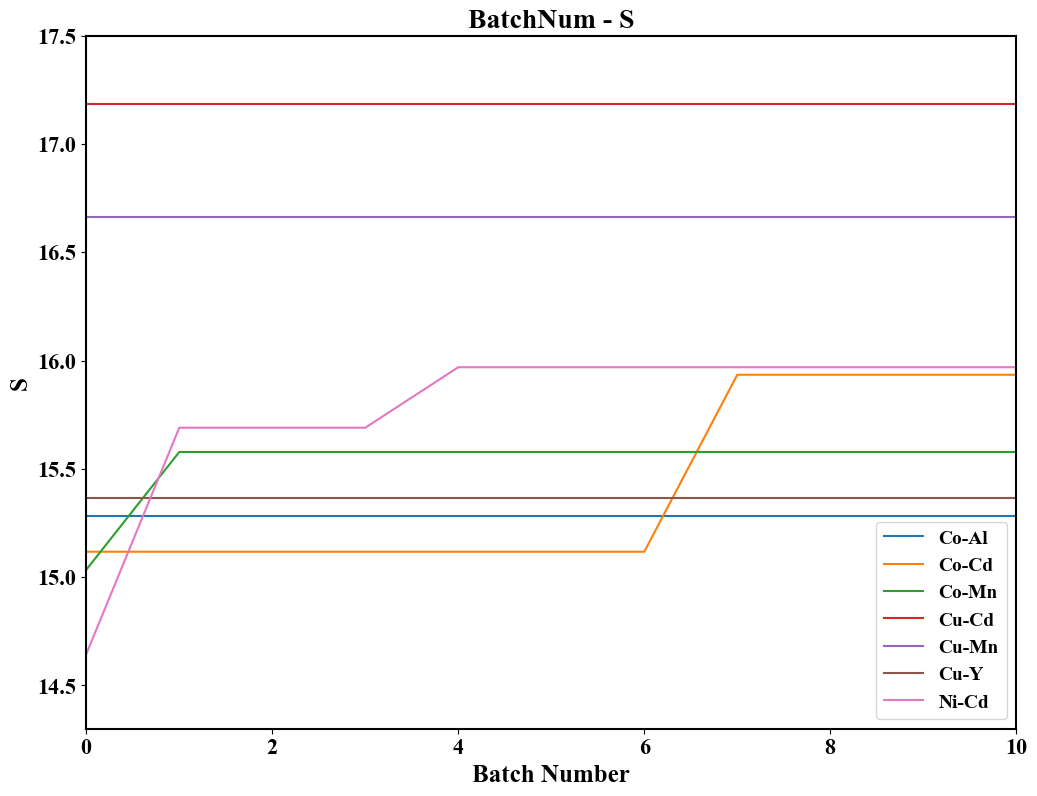

In [42]:
plt.figure(figsize=(12, 9))
metal_combo_labels = ['-'.join(np.array(combo)[:2]) for combo in metal_combo]

for i in range(7):
    plt.plot(metal_results[i], label=metal_combo_labels[i])

ax = plt.gca()  
for spine in ax.spines.values():
    spine.set_linewidth(1.5)  
# 设置X轴和Y轴的范围
plt.xlim(0, 10)  # 设置X轴的范围从0到10
plt.ylim(14.3, 17.5)  # 设置Y轴的范围从-10到10

plt.xticks(fontsize=16, fontname='Times New Roman',fontweight='bold')  # 设置X轴刻度标签的字号和加粗
plt.yticks(fontsize=16,fontname='Times New Roman', fontweight='bold')  # 设置Y轴刻度标签的字号和加粗

plt.title('BatchNum - S', fontname='Times New Roman', fontweight='bold', fontsize=20)
plt.xlabel('Batch Number', fontname='Times New Roman', fontweight='bold', fontsize=18)
plt.ylabel('S',fontname='Times New Roman', fontweight='bold', fontsize=18)
plt.legend(loc='lower right',prop={'family': 'Times New Roman', 'weight': 'bold' ,'size': 14})
plt.show()
